# Customer Churn Prediction

## Project Overview

This project analyzes customer churn for a telecommunications company and builds machine learning models to identify customers at risk of leaving.

The analysis combines exploratory data analysis, data preprocessing, classification modeling, model evaluation, cross-validation, and model interpretation.

### Objectives

- Explore customer characteristics associated with churn
- Prepare categorical and numerical data for machine learning
- Compare Logistic Regression, Decision Tree, and Random Forest models
- Evaluate models using Accuracy, Precision, Recall, F1 Score, and ROC-AUC
- Validate model performance using 5-fold cross-validation
- Interpret the strongest associations with predicted churn

## 1. Data Loading and Initial Inspection

The dataset contains customer-level information including demographics, account characteristics, subscribed services, billing information, and churn status.

In this section, the dataset is loaded and inspected to understand its structure, data types, and potential data quality issues.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 2. Data Cleaning and Preparation

The dataset is checked for data quality issues before analysis. `TotalCharges` is converted to a numeric variable, with invalid or missing values identified and handled appropriately. Duplicate observations are also checked to ensure the dataset is ready for exploratory analysis and modeling.

In [5]:
pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum()

np.int64(11)

In [6]:
df[pd.to_numeric(df["TotalCharges"], errors="coerce").isna()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [7]:
# Convert TotalCharges to numeric.
# Missing values correspond to customers with tenure = 0,
# so TotalCharges is set to 0 for these new customers.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["customerID"].duplicated().sum()

np.int64(0)

## 3. Exploratory Data Analysis

Exploratory data analysis is used to understand the distribution of customer churn and examine how churn varies across important customer characteristics.

The analysis focuses on:

- Overall churn distribution
- Contract type
- Customer tenure
- Monthly charges
- Internet service type

### 3.1 Churn Distribution

The target variable is moderately imbalanced. Approximately **26.5% of customers churned**, while **73.5% remained**. This imbalance is considered when evaluating the classification models, so metrics beyond accuracy—particularly precision, recall, F1 score, and ROC-AUC—are used.

In [10]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [11]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

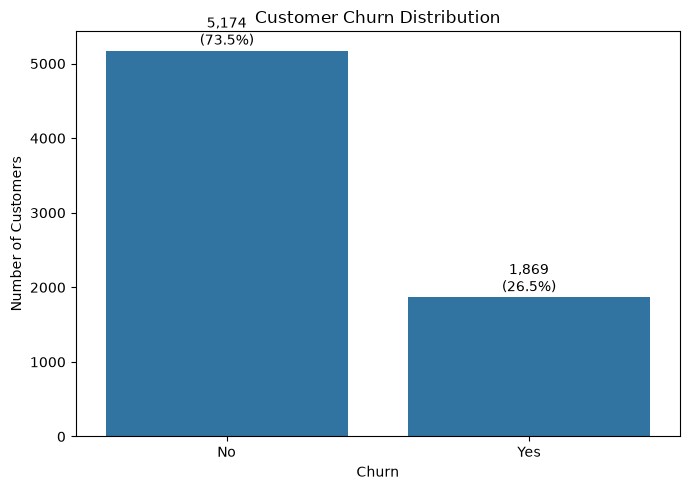

In [12]:
churn_counts = df["Churn"].value_counts()
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=churn_counts.index, y=churn_counts.values)

for i, count in enumerate(churn_counts.values):
    percentage = churn_percentages.iloc[i]
    ax.text(
        i,
        count + 80,
        f"{count:,}\n({percentage:.1f}%)",
        ha="center"
    )

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    "../figures/churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 3.2 Churn by Contract Type

Contract type shows a strong association with customer churn. **Month-to-month customers have the highest observed churn rate (42.7%)**, compared with **11.3% for one-year contracts** and **2.8% for two-year contracts**.

This suggests that customers with longer-term contracts are substantially less likely to churn in this dataset. These results describe an association and should not be interpreted as evidence that contract type itself causes the difference in churn.

In [13]:
contract_churn = (
    df.groupby("Contract")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .sort_values(ascending=False)
)

contract_churn

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64

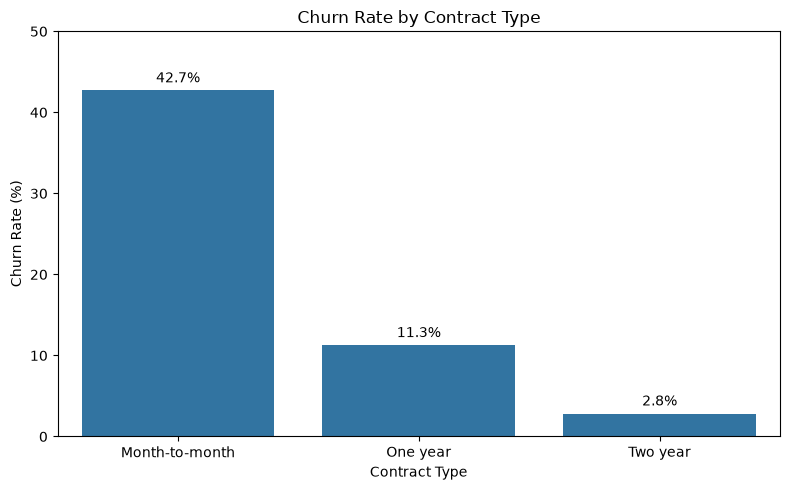

In [14]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

for i, rate in enumerate(contract_churn.values):
    ax.text(
        i,
        rate + 1,
        f"{rate:.1f}%",
        ha="center"
    )

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.tight_layout()

plt.savefig(
    "../figures/churn_by_contract_type.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 3.3 Customer Tenure

Customer tenure differs substantially between customers who churned and those who remained. Customers who churned generally have **shorter tenure**, while non-churning customers tend to have been with the company for longer.

This indicates that churn is more common among relatively newer customers in this dataset, making tenure a potentially informative feature for churn prediction.

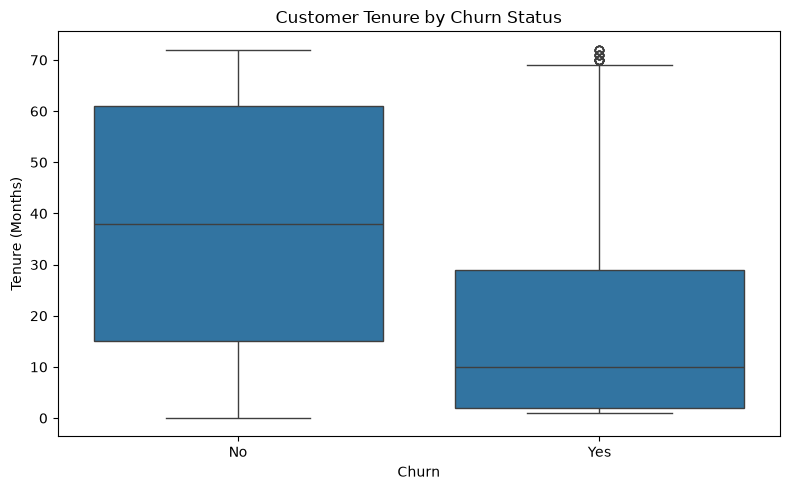

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()

plt.savefig(
    "../figures/tenure_by_churn.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 3.4 Monthly Charges

Customers who churned have higher monthly charges on average. The mean monthly charge is approximately **74.44** for churned customers compared with **61.27** for customers who remained.

This indicates an association between higher monthly charges and churn in the observed data. However, this relationship should not be interpreted as causal, since monthly charges are also related to other customer characteristics and subscribed services.

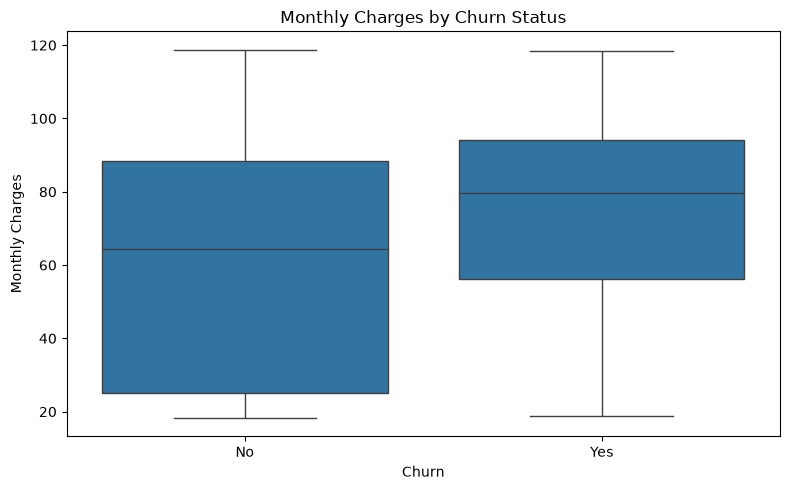

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [17]:
df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median"])

,mean,median
Churn,,
No,61.265124,64.425
Yes,74.441332,79.650


### 3.5 Churn by Internet Service Type

Churn rates also vary across internet service types. Customers using **fiber optic service have the highest observed churn rate (41.9%)**, compared with **19.0% for DSL customers** and **7.4% for customers without internet service**.

This suggests that internet service type is associated with churn behavior in the dataset and may provide useful predictive information. These differences represent observed associations rather than causal effects.

In [18]:
internet_churn = (
    df.groupby("InternetService")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .sort_values(ascending=False)
)

internet_churn

InternetService
Fiber optic    41.892765
DSL            18.959108
No              7.404980
Name: Churn, dtype: float64

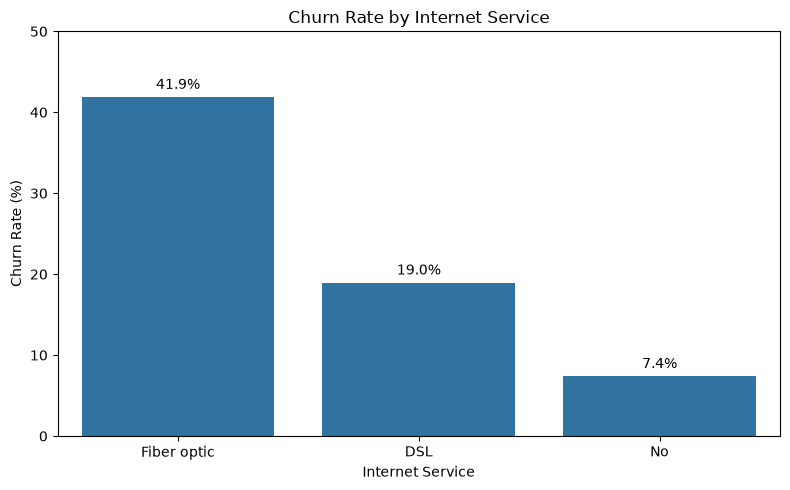

In [19]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values
)

for i, rate in enumerate(internet_churn.values):
    ax.text(
        i,
        rate + 1,
        f"{rate:.1f}%",
        ha="center"
    )

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

## 4. Data Preprocessing and Train/Test Split

The data is prepared for machine learning by separating the predictors from the target variable. The customer identifier is excluded because it does not provide meaningful predictive information, and the churn target is encoded as a binary variable (`0 = No`, `1 = Yes`).

Categorical and numerical features are identified separately. Categorical variables are one-hot encoded, while numerical variables are standardized. The data is then divided into training and test sets using stratified sampling to preserve the churn distribution.

In [20]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("X shape:", X.shape)
print("y shape:", y.shape)
y.value_counts()

X shape: (7043, 19)
y shape: (7043,)


Churn
0    5174
1    1869
Name: count, dtype: int64

In [21]:
categorical_cols = X.select_dtypes(include=["object", "string"]).columns
numerical_cols = X.select_dtypes(exclude=["object", "string"]).columns

print("Categorical columns:")
print(categorical_cols.tolist())

print("\nNumerical columns:")
print(numerical_cols.tolist())

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [22]:
import sklearn

print(sklearn.__version__)

1.9.1


In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", StandardScaler(), numerical_cols)
    ]
)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining churn rate:")
print(y_train.value_counts(normalize=True))

print("\nTest churn rate:")
print(y_test.value_counts(normalize=True))

Training set: (5634, 19)
Test set: (1409, 19)

Training churn rate:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Test churn rate:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


## 5. Model Training and Evaluation

Three classification models are trained and compared:

- Logistic Regression
- Decision Tree
- Random Forest

Each model is evaluated on the held-out test set using Accuracy, Precision, Recall, F1 Score, and ROC-AUC. ROC-AUC is particularly useful here because it evaluates the model's ability to distinguish between churners and non-churners across classification thresholds.

### 5.1 Logistic Regression

Logistic Regression is used as an interpretable baseline classification model. The preprocessing and classifier are combined in a scikit-learn pipeline to ensure that the same transformations are applied consistently during training and prediction.

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

logistic_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

In [26]:
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [27]:
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 churn probabilities:")
print(y_prob[:10])

First 10 predictions:
[0 1 0 0 0 1 0 0 0 0]

First 10 churn probabilities:
[0.04591993 0.68371345 0.05893985 0.40183529 0.02142426 0.60297803
 0.44762898 0.13033554 0.00280355 0.39473874]


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1 Score:", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

Accuracy: 0.806
Precision: 0.657
Recall: 0.559
F1 Score: 0.604
ROC-AUC: 0.842


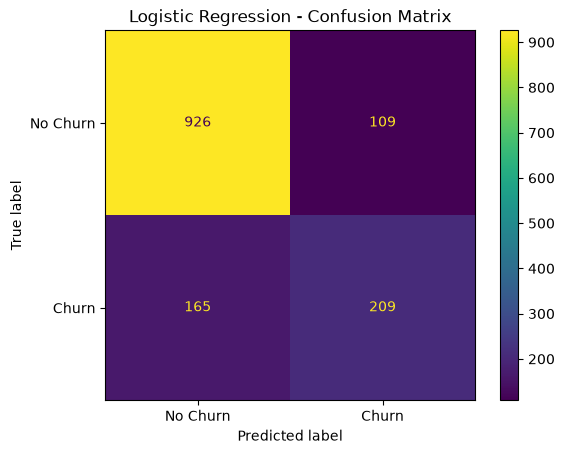

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

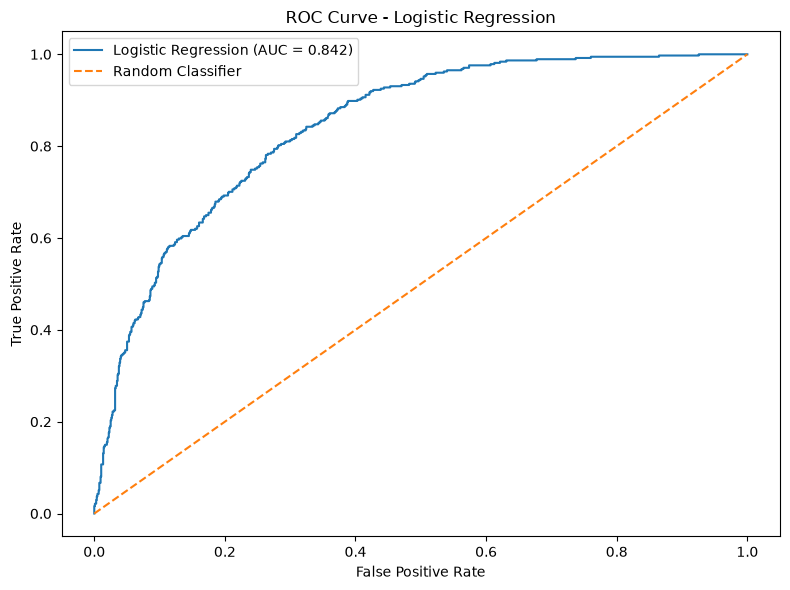

In [30]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.tight_layout()

plt.savefig(
    "../figures/logistic_regression_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.2 Decision Tree

A Decision Tree classifier is trained as a nonlinear alternative to Logistic Regression. The tree is limited to a maximum depth of 5 to reduce model complexity and help control overfitting.

The model is evaluated using the same metrics as Logistic Regression to allow a consistent comparison.

In [31]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            random_state=42,
            max_depth=5
        ))
    ]
)

tree_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [32]:
tree_pred = tree_model.predict(X_test)
tree_prob = tree_model.predict_proba(X_test)[:, 1]

print("Decision Tree Results")
print("Accuracy:", round(accuracy_score(y_test, tree_pred), 3))
print("Precision:", round(precision_score(y_test, tree_pred), 3))
print("Recall:", round(recall_score(y_test, tree_pred), 3))
print("F1 Score:", round(f1_score(y_test, tree_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, tree_prob), 3))

Decision Tree Results
Accuracy: 0.798
Precision: 0.635
Recall: 0.567
F1 Score: 0.599
ROC-AUC: 0.83


### 5.3 Random Forest

A Random Forest classifier is trained as an ensemble-based alternative. By combining predictions from multiple decision trees, Random Forest can capture nonlinear relationships while reducing the instability of a single decision tree.

The model is evaluated using the same test-set metrics to enable direct comparison with Logistic Regression and the Decision Tree.

In [33]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42
        ))
    ]
)

rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [34]:
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Results")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 3))
print("Precision:", round(precision_score(y_test, rf_pred), 3))
print("Recall:", round(recall_score(y_test, rf_pred), 3))
print("F1 Score:", round(f1_score(y_test, rf_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 3))

Random Forest Results
Accuracy: 0.788
Precision: 0.629
Recall: 0.489
F1 Score: 0.55
ROC-AUC: 0.817


### 5.4 Test Set Model Comparison

The three models are compared on the held-out test set using the same evaluation metrics.

Logistic Regression achieves the highest overall test performance among the evaluated models, with an **ROC-AUC of 0.842** and **F1 score of 0.604**. The Decision Tree achieves a similar F1 score of **0.599** and the highest recall at **0.567**, while the Random Forest performs lower on the selected metrics.

In [35]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, tree_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, tree_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, tree_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1": [
        f1_score(y_test, y_pred),
        f1_score(y_test, tree_pred),
        f1_score(y_test, rf_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, tree_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

results.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.806,0.657,0.559,0.604,0.842
1,Decision Tree,0.798,0.635,0.567,0.599,0.830
2,Random Forest,0.788,0.629,0.489,0.550,0.817


## 6. Cross-Validation

To evaluate the stability of model performance beyond a single train/test split, 5-fold cross-validation is performed on the training data using ROC-AUC as the evaluation metric.

The cross-validation results are compared with the held-out test performance to assess how consistently each model generalizes across different subsets of the data.

In [36]:
from sklearn.model_selection import cross_val_score

In [37]:
logistic_cv = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
)

print("ROC-AUC for each fold:", logistic_cv)
print("Mean ROC-AUC:", logistic_cv.mean())
print("Standard deviation:", logistic_cv.std())

ROC-AUC for each fold: [0.86360332 0.85326693 0.85101708 0.83620523 0.82430148]
Mean ROC-AUC: 0.8456788054729003
Standard deviation: 0.01381378704722736


In [38]:
tree_cv = cross_val_score(
    tree_model,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
)

rf_cv = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
)

print("Decision Tree")
print("Mean ROC-AUC:", round(tree_cv.mean(), 3))
print("Standard deviation:", round(tree_cv.std(), 3))

print("\nRandom Forest")
print("Mean ROC-AUC:", round(rf_cv.mean(), 3))
print("Standard deviation:", round(rf_cv.std(), 3))

Decision Tree
Mean ROC-AUC: 0.826
Standard deviation: 0.012

Random Forest
Mean ROC-AUC: 0.824
Standard deviation: 0.013


### 6.1 Cross-Validation Results

The 5-fold cross-validation results are consistent with the held-out test performance:

- **Logistic Regression:** Test ROC-AUC = 0.842, CV ROC-AUC = 0.846
- **Decision Tree:** Test ROC-AUC = 0.830, CV ROC-AUC = 0.826
- **Random Forest:** Test ROC-AUC = 0.817, CV ROC-AUC = 0.824

Logistic Regression achieves the highest ROC-AUC among the three evaluated models on both the test set and cross-validation. The small differences between test and cross-validation scores suggest that performance is reasonably stable across different data splits.

In [39]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [0.806, 0.798, 0.788],
    "Precision": [0.657, 0.635, 0.629],
    "Recall": [0.559, 0.567, 0.489],
    "F1 Score": [0.604, 0.599, 0.550],
    "Test ROC-AUC": [0.842, 0.830, 0.817],
    "CV ROC-AUC": [
        logistic_cv.mean(),
        tree_cv.mean(),
        rf_cv.mean()
    ]
})

results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,Test ROC-AUC,CV ROC-AUC
0,Logistic Regression,0.806,0.657,0.559,0.604,0.842,0.846
1,Decision Tree,0.798,0.635,0.567,0.599,0.830,0.826
2,Random Forest,0.788,0.629,0.489,0.550,0.817,0.824


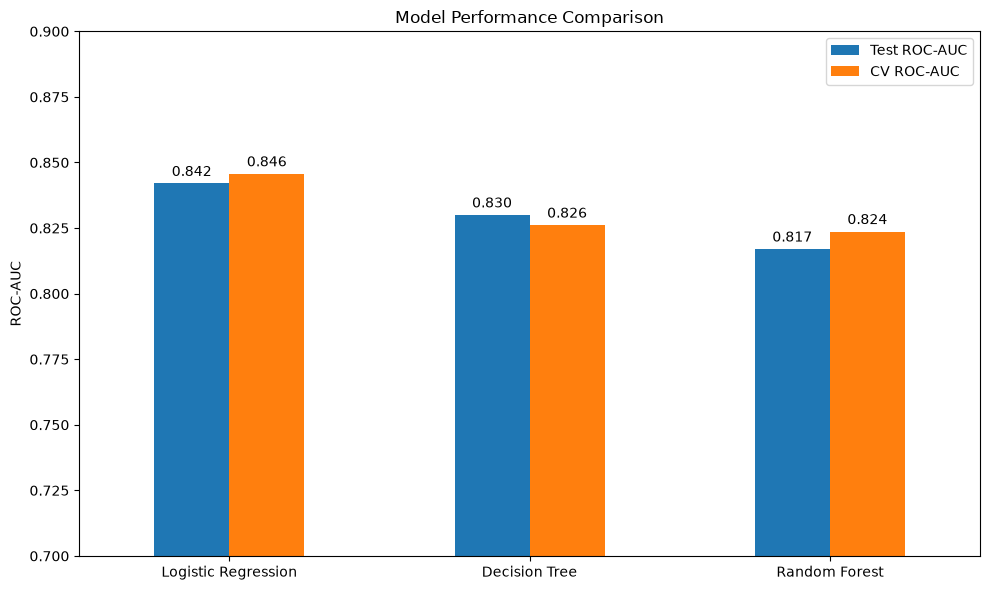

In [40]:
comparison = results.set_index("Model")[["Test ROC-AUC", "CV ROC-AUC"]]

ax = comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("ROC-AUC")
plt.xlabel("")
plt.ylim(0.7, 0.9)
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()

plt.savefig(
    "../figures/model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Model Interpretation

Because Logistic Regression achieved the highest ROC-AUC among the evaluated models, its coefficients are examined to better understand which features are associated with predicted churn.

Positive coefficients are associated with higher predicted churn probability, while negative coefficients are associated with lower predicted churn probability, conditional on the other features in the model.

These coefficients describe associations within the fitted model and should not be interpreted as causal effects.

In [41]:
# Get feature names after preprocessing
feature_names = (
    logistic_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get Logistic Regression coefficients
coefficients = (
    logistic_model
    .named_steps["classifier"]
    .coef_[0]
)

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort from strongest positive to strongest negative
coef_df = coef_df.sort_values(
    "Coefficient",
    ascending=False
)

coef_df

,Feature,Coefficient
12,cat__InternetService_Fiber optic,0.634195
32,cat__Contract_Month-to-month,0.582883
44,num__TotalCharges,0.536253
31,cat__StreamingMovies_Yes,0.200938
28,cat__StreamingTV_Yes,0.200481
39,cat__PaymentMethod_Electronic check,0.197867
14,cat__OnlineSecurity_No,0.156279
23,cat__TechSupport_No,0.131503
10,cat__MultipleLines_Yes,0.104649
41,num__SeniorCitizen,0.053449


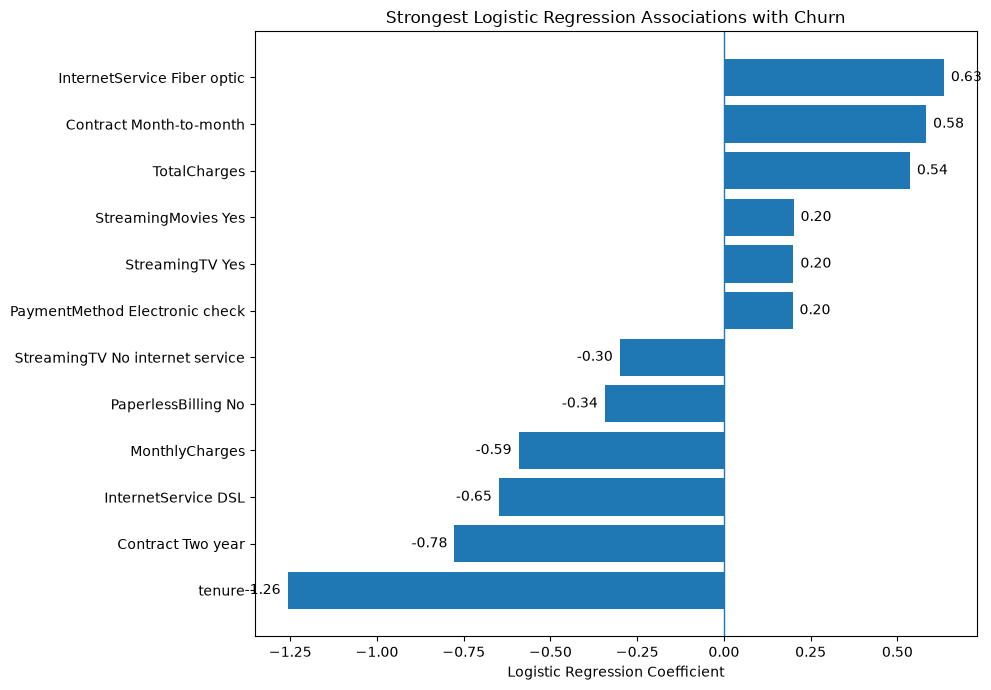

In [42]:
# 6 strongest positive and 6 strongest negative coefficients
top_positive = coef_df.nlargest(6, "Coefficient")
top_negative = coef_df.nsmallest(6, "Coefficient")

top_features = pd.concat([top_negative, top_positive])

# Make feature names cleaner
top_features = top_features.copy()

top_features["Feature"] = (
    top_features["Feature"]
    .str.replace("cat__", "", regex=False)
    .str.replace("num__", "", regex=False)
    .str.replace("_", " ", regex=False)
)

# Sort for horizontal plot
top_features = top_features.sort_values("Coefficient")

plt.figure(figsize=(10, 7))

bars = plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, linewidth=1)

plt.title("Strongest Logistic Regression Associations with Churn")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("")

for bar, value in zip(bars, top_features["Coefficient"]):
    if value >= 0:
        plt.text(
            value + 0.02,
            bar.get_y() + bar.get_height()/2,
            f"{value:.2f}",
            va="center"
        )
    else:
        plt.text(
            value - 0.02,
            bar.get_y() + bar.get_height()/2,
            f"{value:.2f}",
            va="center",
            ha="right"
        )

plt.tight_layout()

plt.savefig(
    "../figures/logistic_regression_churn_associations.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 7.1 Key Model Associations

The Logistic Regression model highlights several notable associations with predicted churn:

- **Shorter tenure** is strongly associated with higher predicted churn, consistent with the exploratory analysis.
- **Month-to-month contracts** are associated with higher predicted churn, while **two-year contracts** are associated with lower predicted churn.
- **Fiber optic internet service** shows a positive association with predicted churn.
- **Electronic check payment** also shows a positive association with predicted churn.

Because the model includes multiple correlated predictors and uses regularization, individual coefficients should be interpreted conditionally rather than as isolated effects. In particular, coefficient direction may differ from patterns observed in the exploratory analysis.

Overall, the results suggest that customer tenure, contract structure, and service characteristics contain useful information for identifying customers at higher risk of churn.

## 8. Conclusion and Limitations

### Conclusion

This project analyzed customer churn using exploratory data analysis and three classification models: Logistic Regression, Decision Tree, and Random Forest.

The analysis identified clear churn patterns across customer characteristics. Churn was particularly high among customers with month-to-month contracts, shorter tenure, and fiber optic internet service.

Among the evaluated models, **Logistic Regression achieved the highest ROC-AUC**, with **0.842 on the test set** and **0.846 in 5-fold cross-validation**. The similarity between test and cross-validation performance suggests reasonably stable predictive performance across different data splits.

The results demonstrate how customer data can be transformed into actionable churn-risk insights using a reproducible machine learning workflow.

### Limitations

- The analysis identifies statistical associations and does not establish causal relationships.
- The dataset represents a specific telecommunications customer sample, so results may not generalize to other companies or populations.
- Model performance depends on the available features and could potentially improve with additional behavioral or customer interaction data.
- The classification threshold was not optimized for a specific business objective or cost of false positives and false negatives.
- More extensive hyperparameter tuning and additional models could be explored in future work.